In [1]:
# ========== LES OUTILS ==========
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

print(" Les outils sont prêts !")

 Les outils sont prêts !


In [2]:
# ========== LES DONNÉES  ==========
from sklearn.datasets import fetch_california_housing

# Aller chercher le carnet d'exemples et le transformer en tableau
donnees = fetch_california_housing(as_frame=True)
maisons = donnees.frame

print("Nombre de maisons :", len(maisons))
maisons.head()

Nombre de maisons : 20640


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:


# 1. Le bilan de santé du tableau
maisons.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [4]:
# 2. Chercher les cases vides
print(" Cases vides par colonne :")
print(maisons.isnull().sum())

 Cases vides par colonne :
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


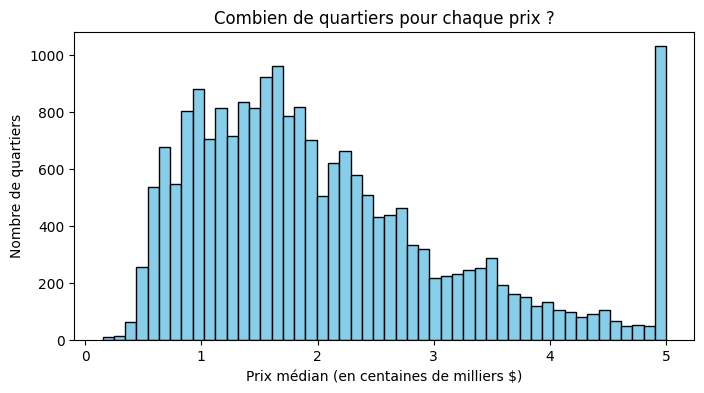

In [5]:
# 3. Dessiner la répartition des prix
plt.figure(figsize=(8, 4))
plt.hist(maisons["MedHouseVal"], bins=50, color="skyblue", edgecolor="black")
plt.title("Combien de quartiers pour chaque prix ?")
plt.xlabel("Prix médian (en centaines de milliers $)")
plt.ylabel("Nombre de quartiers")
plt.show()

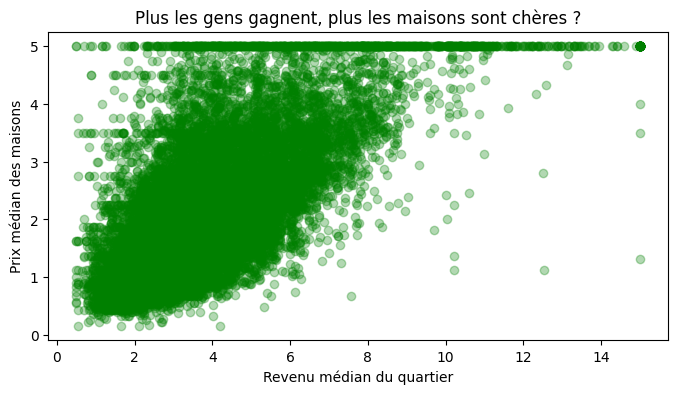

In [6]:
# 4. Le revenu influence-t-il le prix ?
plt.figure(figsize=(8, 4))
plt.scatter(maisons["MedInc"], maisons["MedHouseVal"], alpha=0.3, color="green")
plt.title("Plus les gens gagnent, plus les maisons sont chères ?")
plt.xlabel("Revenu médian du quartier")
plt.ylabel("Prix médian des maisons")
plt.show()

In [7]:


X = maisons.drop("MedHouseVal", axis=1)
y = maisons["MedHouseVal"]

print("Indices :", X.shape)
print("Réponses :", y.shape)

Indices : (20640, 8)
Réponses : (20640,)


In [8]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entraînement :", X_train.shape)  # (16512, 8)
print("Test :", X_test.shape)         # (4128, 8)

Entraînement : (16512, 8)
Test : (4128, 8)


In [9]:

from sklearn.linear_model import LinearRegression

modele = LinearRegression()      # 1. Créer le cerveau (vide)
modele.fit(X_train, y_train)     # 2. Le faire étudier sur les exemples
print("Le modèle a fini d'apprendre !")

Le modèle a fini d'apprendre !


In [10]:

predictions = modele.predict(X_test)   # Le modèle devine

# Calculer son erreur moyenne (RMSE)
from sklearn.metrics import mean_squared_error
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print(" Erreur moyenne du modèle (RMSE) :", round(rmse, 3))

 Erreur moyenne du modèle (RMSE) : 0.746


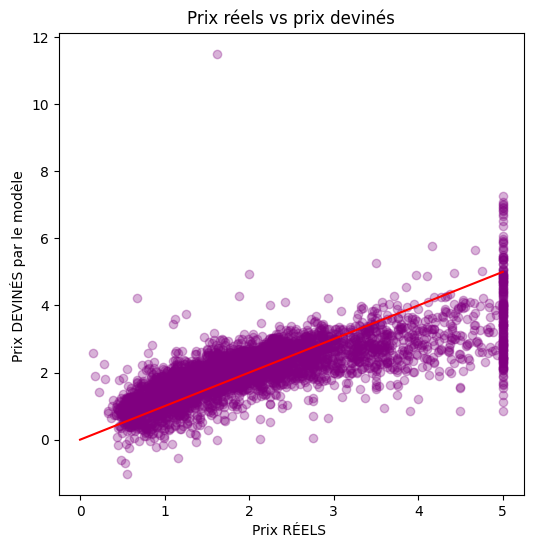

In [11]:
# Prix réels vs prix devinés
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.3, color="purple")
plt.plot([0, 5], [0, 5], color="red")
plt.title("Prix réels vs prix devinés")
plt.xlabel("Prix RÉELS ")
plt.ylabel("Prix DEVINÉS par le modèle ")
plt.show()

In [12]:
from sklearn.dummy import DummyRegressor

idiot = DummyRegressor(strategy="mean")
idiot.fit(X_train, y_train)
rmse_idiot = np.sqrt(mean_squared_error(y_test, idiot.predict(X_test)))

print("RMSE du modèle idiot :", round(rmse_idiot, 3))
print("RMSE de ma régression :", round(rmse, 3))
print("Part de variance expliquée (R²) ≈", round(1 - (rmse / rmse_idiot) ** 2, 3))

RMSE du modèle idiot : 1.145
RMSE de ma régression : 0.746
Part de variance expliquée (R²) ≈ 0.576


In [13]:

rmse_lineaire = rmse
print("RMSE régression linéaire :", round(rmse_lineaire, 3))

RMSE régression linéaire : 0.746


In [14]:
from sklearn.ensemble import RandomForestRegressor

foret = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
foret.fit(X_train, y_train)                 #  100 arbres

pred_foret = foret.predict(X_test)
rmse_foret = np.sqrt(mean_squared_error(y_test, pred_foret))
print(" RMSE Random Forest :", round(rmse_foret, 3))

 RMSE Random Forest : 0.505


In [15]:
resultats = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Random Forest"],
    "RMSE": [rmse_lineaire, rmse_foret],
})
resultats["Erreur typique ($)"] = (resultats["RMSE"] * 100000).round(0)
print(resultats)

                Modèle      RMSE  Erreur typique ($)
0  Régression linéaire  0.745581             74558.0
1        Random Forest  0.505340             50534.0


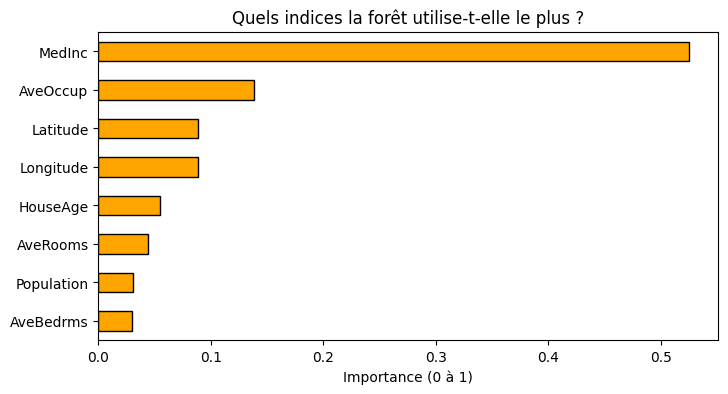

In [16]:
importance = pd.Series(foret.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh", color="orange", edgecolor="black")
plt.title("Quels indices la forêt utilise-t-elle le plus ?")
plt.xlabel("Importance (0 à 1)")
plt.show()

In [17]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, learning_rate=0.1,
                   max_depth=6, random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)
rmse_xgb = np.sqrt(mean_squared_error(y_test, pred_xgb))
print(" RMSE XGBoost :", round(rmse_xgb, 3))

 RMSE XGBoost : 0.45


In [18]:
resultats = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Random Forest", "XGBoost"],
    "RMSE": [rmse_lineaire, rmse_foret, rmse_xgb],
})
resultats["Erreur typique ($)"] = (resultats["RMSE"] * 100000).round(0)
resultats["R²"] = (1 - (resultats["RMSE"] / rmse_idiot) ** 2).round(3)
print(resultats)

                Modèle      RMSE  Erreur typique ($)     R²
0  Régression linéaire  0.745581             74558.0  0.576
1        Random Forest  0.505340             50534.0  0.805
2              XGBoost  0.449813             44981.0  0.846


In [19]:
resultats.to_csv("resultats_modeles.csv", index=False)

# Nouvelle section